# PredCls trên GQA
Bảng test đọc kết quả đã lưu. Hình phân tích lỗi dùng hai checkpoint seed 42, cache CLIP của validation và ảnh gốc trong workspace. Các cell chạy tuần tự trên CPU từ gốc repo hoặc từ thư mục notebooks.

In [1]:
from pathlib import Path
import json
import os
import sys
import torch
import pandas as pd

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'tools/gqa_test_v1').is_dir())
os.chdir(root)
sys.path.insert(0, str(root))
from tools.gqa_test_v1.runner import build, read  # noqa: E402 (requires repository path above)

torch.set_num_threads(2)
report = Path('reports/level2/gqa-test-v1')
figures = Path('report_latex/figures')
metrics = ['R@50', 'R@100', 'mR@50', 'mR@100']
names = {'mlp': 'MLP', 'gat': 'GAT', 'gat-kg': 'GAT + KG', 'pe-ce': 'PE-CE',
         'pe-pl': 'PE-PL', 'pe-plpr': 'PE-PLPR', 'pe-ce-aligng': 'PE-CE + AlignG',
         'edge-only': 'Edge-only', 'pe-plpr-aligng': 'PE-PLPR + AlignG'}
summary = read(report / 'summary.json')
assert summary['complete'] and summary['completed'] == 27
rows = []
for model in names:
    item = summary['models'][model]
    assert item['seeds'] == [42, 123, 3407]
    for seed in item['seeds']:
        result = read(report / model / str(seed) / 'result.json')
        assert result['status'] == 'PASS' and result['test_images'] == 10696
        rows.append(dict(model=model, seed=seed, **{m: 100*result['metrics']['gc'][m] for m in metrics}))

scores = pd.DataFrame(rows).set_index(['model','seed'])
means = scores.groupby('model').mean().loc[list(names)]
sds = scores.groupby('model').std().loc[list(names)]
display(means.round(2), sds.round(2))

/workspace/workspace/semantic-graph-editing/myenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,R@50,R@100,mR@50,mR@100
model,,,,
mlp,76.86,87.39,3.58,5.88
gat,77.46,87.86,2.97,4.88
gat-kg,77.42,87.84,3.04,4.85
pe-ce,78.11,88.40,2.93,4.68
pe-pl,78.21,88.48,3.40,5.48
pe-plpr,78.00,88.24,4.07,6.78
pe-ce-aligng,78.03,88.26,3.52,5.68
edge-only,77.79,88.00,4.31,7.00
pe-plpr-aligng,78.06,88.22,4.62,7.44


,R@50,R@100,mR@50,mR@100
model,,,,
mlp,0.45,0.29,0.38,0.46
gat,0.11,0.10,0.24,0.19
gat-kg,0.04,0.05,0.19,0.22
pe-ce,0.17,0.13,0.16,0.39
pe-pl,0.09,0.03,0.22,0.37
pe-plpr,0.03,0.05,0.20,0.18
pe-ce-aligng,0.36,0.35,0.32,0.45
edge-only,0.02,0.02,0.19,0.17
pe-plpr-aligng,0.07,0.06,0.57,0.81


In [2]:
def latex_number(value):
    return f'{value:.2f}'.replace('.', '{,}')

table = []
for key, label in names.items():
    cells = [label]
    for metric in metrics:
        mean, sd = means.loc[key, metric], sds.loc[key, metric]
        assert abs(mean - 100*summary['models'][key]['gc'][metric]['mean']) < 1e-8
        assert abs(sd - 100*summary['models'][key]['gc'][metric]['std_sample']) < 1e-8
        field = latex_number(mean) + r'\pm' + latex_number(sd)
        if mean == means[metric].max():
            field = r'\mathbf{' + field + '}'
        cells.append('$' + field + '$')
    table.append(' & '.join(cells) + r' \\')
table.append(r'\bottomrule')
(figures / 'gqa-test-rows.tex').write_text('\n'.join(table) + '\n')

892

## Phân bố predicate trên train
Đếm các dòng chú thích sau chuẩn hóa trên toàn bộ 69.942 ảnh train, sắp giảm dần theo tần suất.

3,157,838/3,541,725 = 89.16%
42/310 predicate có dưới 20 chú thích.


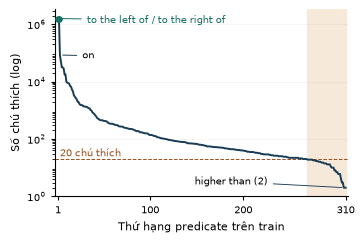

In [3]:
import matplotlib.pyplot as plt

audit = read('reports/level2/gqa-scale-audit-v1.json')
counts = pd.Series({p['name']: p['annotation_rows']['train_full'] for p in audit['per_predicate']})
counts = counts.sort_index().sort_values(ascending=False, kind='stable')
assert len(counts) == 310 and counts.min() > 0
assert counts.sum() == audit['summaries']['train_full']['gt_annotation_rows']
directional = counts.loc[['to the left of', 'to the right of']]
rare = counts[counts < 20]
print(f"{directional.sum():,}/{counts.sum():,} = {100 * directional.sum() / counts.sum():.2f}%")
print(f"{len(rare)}/{len(counts)} predicate có dưới 20 chú thích.")

ink, teal, ochre = '#193c55', '#177063', '#985020'
ranks = pd.Series(range(1, len(counts) + 1), index=counts.index)
fig, ax = plt.subplots(figsize=(3.53, 2.32), layout='constrained')
ax.set_yscale('log')
ax.axvspan(ranks[rare.index[0]] - .5, len(counts) + .5, color='#f6e9d9', zorder=0)
ax.axhline(20, color=ochre, linestyle='--', linewidth=.7)
ax.plot(ranks, counts, color=ink, lw=1.4)
ax.scatter(ranks[directional.index], directional, s=14, color=teal, zorder=3)
ax.annotate('to the left of / to the right of', (2, directional.iloc[0]), xytext=(32, 1.1e6),
            fontsize=7.2, color=teal, arrowprops=dict(arrowstyle='-', lw=.7, color=teal))
ax.annotate('on', (3, counts['on']), xytext=(27, 6.5e4), fontsize=7.2,
            arrowprops=dict(arrowstyle='-', lw=.7, color=ink))
ax.annotate('higher than (2)', (ranks['higher than'], counts['higher than']),
            xytext=(187, 2.6), fontsize=7, ha='center',
            arrowprops=dict(arrowstyle='-', lw=.65, color=ink))
ax.text(3, 25, '20 chú thích', color=ochre, fontsize=7)
ax.set(xlim=(-2, 312), ylim=(1, 3.3e6), xticks=[1,100,200,310],
       yticks=[1,100,10000,1000000], xlabel='Thứ hạng predicate trên train',
       ylabel='Số chú thích (log)')
ax.tick_params(labelsize=7.5, length=3)
ax.xaxis.label.set_size(8)
ax.yaxis.label.set_size(8)
ax.spines[['top','right']].set_visible(False)
ax.grid(axis='y', alpha=.18, lw=.5)
fig.savefig(figures / 'gqa-train-predicates.pdf', metadata={'CreationDate': None})
plt.show()
plt.close(fig)

## Cách chọn 5 ca Hit và 5 ca Miss
Duyệt ảnh validation theo thứ tự manifest, rồi duyệt các dòng ground truth theo thứ tự đã lưu. Mỗi ảnh đóng góp tối đa một ca vào từng nhóm. Trong mỗi nhóm, mỗi predicate chỉ xuất hiện một lần để có nhiều loại ví dụ. Đúng/sai tính theo GC top-50 của PE-PLPR + AlignG. Chỉ chọn các cặp mà kết quả trên đúng instance thống nhất với bộ chấm IoU của dự án. PE-PLPR được chấm sau khi chọn ca.

In [4]:
from experiments.aligng_fast_v1.batching import collate, model_inputs
from src.datasets.gqa_full import GQAFullDataset
from src.evaluation.reference_predcls import evaluate_reference_image
from src.knowledge.transe.core import sha256

manifest_path = Path('data/processed/level2/gqa-v1/manifest.json')
manifest = read(manifest_path)
vocab = manifest['vocabulary']
predicates = {i: p for p, i in vocab['predicate_to_idx'].items()}
objects = {i: p for p, i in vocab['label_to_idx'].items()}
directory = Path('data/cache/gqa-full-clip-v1')
metadata = read(directory / 'manifest.json')
assert metadata['identity']['manifest_sha256'] == sha256(manifest_path)
graphs = GQAFullDataset(directory, metadata, 'val')
assert graphs.ids == manifest['splits']['val']
jobs = read(report / 'training-audit.json')['jobs']
def checkpoint(model):
    job, = [j for j in jobs if j['model'] == model and j['seed'] == 42]
    return build(job)  # kiểm SHA-256 và đọc checkpoint trên CPU

aligng, dims = checkpoint('pe-plpr-aligng')
control, _ = checkpoint('pe-plpr')

In [5]:
def pair_predictions(logits):
    scores, labels = logits.softmax(-1)[:, 1:].max(-1)
    return labels + 1, scores.sort(descending=True).indices.argsort() + 1

def gc_hit(logits, graph, row):
    outcome = evaluate_reference_image(
        logits, graph.edge_label_index, graph.gt_relation_index[:, row:row+1],
        graph.gt_predicate[row:row+1], graph.boxes, graph.object_labels, ks=(50,))
    return bool(outcome['hits'][50])

cases = {True: [], False: []}
seen = {True: set(), False: set()}
with torch.inference_mode():
    for graph_index, image_id in enumerate(graphs.ids):
        graph = graphs[graph_index]
        if not graph.gt_predicate.numel():
            continue
        batch = collate([graph], dims['num_classes'])
        logits = aligng(**model_inputs(batch, 'cpu'))
        labels, ranks = pair_predictions(logits)
        indices = {tuple(pair): i for i, pair in enumerate(graph.edge_label_index.T.tolist())}
        chosen = {}
        for row, predicate in enumerate(graph.gt_predicate.tolist()):
            s, o = graph.gt_relation_index[:, row].tolist()
            pair = indices[s, o]
            pred, rank = int(labels[pair]), int(ranks[pair])
            hit = pred == predicate and rank <= 50
            if hit in chosen or len(cases[hit]) == 5 or predicate in seen[hit]:
                continue
            if gc_hit(logits, graph, row) != hit:
                continue
            chosen[hit] = (row, predicate, s, o, pair, pred, rank)
        if chosen:
            baseline = control(graph.x, graph.edge_label_index, graph.object_labels)
            ref_labels, ref_ranks = pair_predictions(baseline)
        for hit, (row, predicate, s, o, pair, pred, rank) in chosen.items():
            seen[hit].add(predicate)
            cases[hit].append(dict(image_id=image_id, graph_index=graph_index, gt_row=row,
                s=s, o=o, subject=objects[int(graph.object_labels[s])], object=objects[int(graph.object_labels[o])],
                gt=predicates[predicate], pred=predicates[pred], rank=rank,
                control=predicates[int(ref_labels[pair])], control_rank=int(ref_ranks[pair]),
                control_hit=gc_hit(baseline, graph, row), boxes=graph.boxes[[s,o]].tolist()))
        if all(len(group) == 5 for group in cases.values()):
            break
assert all(len(group) == 5 for group in cases.values())
for hit, group in cases.items():
    print('GC@50', hit)
    display(pd.DataFrame(group).drop(columns=['boxes']))

GC@50 True


,image_id,graph_index,gt_row,s,o,subject,object,gt,pred,rank,control,control_rank,control_hit
0,1,0,7,0,20,car,shirt,to the right of,to the right of,45,to the right of,40,True
1,1037,1,1,1,2,pan,dough,to the left of,to the left of,40,to the left of,33,True
2,1040,2,3,8,9,sign,window,on,on,7,on,9,True
3,1056,4,0,0,7,person,jeans,wearing,wearing,7,wearing,7,True
4,107904,6,0,0,7,cloud,sky,in,in,6,in,9,True


GC@50 False


,image_id,graph_index,gt_row,s,o,subject,object,gt,pred,rank,control,control_rank,control_hit
0,1,0,0,0,16,car,van,to the left of,to the left of,185,to the left of,195,False
1,1037,1,0,1,2,pan,dough,of,to the left of,40,to the left of,33,False
2,1040,2,0,1,9,balls,window,near,to the left of,12,to the left of,6,False
3,1052,3,0,0,2,alcohol,glass,on,to the left of,5,to the left of,6,False
4,1060,5,1,1,2,window,curtains,to the right of,to the right of,63,to the right of,63,False


## PE-Net và nhánh AlignG trên GQA
Ví dụ validation lấy đúng cặp người và quần jeans ở ảnh 1056. Sơ đồ bám theo hàm forward của PE-Net và FastAlignG.

In [6]:
import hashlib
import io
import zipfile
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.patches import FancyBboxPatch, Rectangle
from PIL import Image
from src.datasets.gqa import image_archive_index

archive = Path('data/raw/gqa/archives/images.zip')
image_index = image_archive_index(archive)

def draw_case_image(ax, row, images):
    image_id = row['image_id']
    graphs[row['graph_index']]  # mở shard của ảnh qua bộ đọc validation
    group = graphs.handles[graphs.locations[image_id]][image_id]
    record = json.loads(group['record'][()].decode())
    jpeg = images.read(image_index[image_id])
    assert hashlib.sha256(jpeg).hexdigest() == group.attrs['jpeg_sha256']
    with Image.open(io.BytesIO(jpeg)) as img:
        ax.imshow(img.convert('RGB'), extent=(0, record['width'], record['height'], 0))
    for (x1, y1, x2, y2), color in zip(row['boxes'], ('#ff453a', '#00afff'), strict=True):
        ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, lw=1.5, ec=color))
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

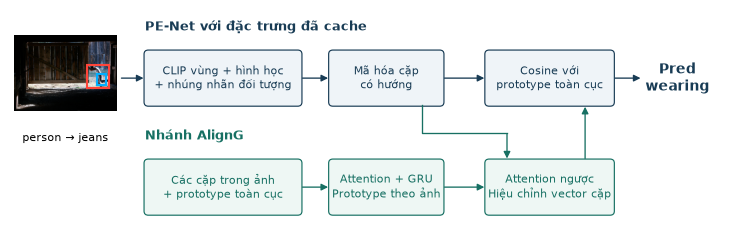

In [7]:
example, = [row for row in cases[True] if row['image_id'] == '1056'
            and (row['subject'], row['object']) == ('person', 'jeans')]
assert example['gt'] == example['pred'] == 'wearing'
fig = plt.figure(figsize=(7.10, 2.18))
ax = fig.add_axes([0, 0, 1, 1], xlim=(0, 100), ylim=(0, 32))
ax.axis('off')

def box(x, y, w, h, label, branch=False):
    color, fill = (teal, '#eef7f4') if branch else (ink, '#eff4f8')
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12,rounding_size=.6',
                                ec=color, fc=fill, lw=.85))
    ax.text(x+w/2, y+h/2, label, ha='center', va='center', fontsize=8, color=color)

def arrow(start, end, branch=False):
    ax.annotate('', xy=end, xytext=start, arrowprops=dict(
        arrowstyle='-|>', lw=.95, shrinkA=1, shrinkB=1, color=teal if branch else ink))

photo = fig.add_axes([.006, .47, .145, .48])
with zipfile.ZipFile(archive) as images:
    draw_case_image(photo, example, images)
ax.text(7.8, 14, 'person → jeans', fontsize=8, ha='center', va='top')
ax.text(19, 29, 'PE-Net với đặc trưng đã cache', fontsize=9, weight='bold', color=ink)
box(19, 18, 22, 8, 'CLIP vùng + hình học\n+ nhúng nhãn đối tượng')
box(45, 18, 16, 8, 'Mã hóa cặp\ncó hướng')
box(67, 18, 18, 8, 'Cosine với\nprototype toàn cục')
ax.text(94, 22, f"Pred\n{example['pred']}", ha='center', va='center', color=ink, fontsize=10, weight='bold')
for start, end in [(15.5,19), (41,45), (61,67), (85,89)]:
    arrow((start,22), (end,22))

ax.text(19, 13, 'Nhánh AlignG', fontsize=9, weight='bold', color=teal)
box(19, 2, 22, 8, 'Các cặp trong ảnh\n+ prototype toàn cục', branch=True)
box(45, 2, 16, 8, 'Attention + GRU\nPrototype theo ảnh', branch=True)
box(67, 2, 18, 8, 'Attention ngược\nHiệu chỉnh vector cặp', branch=True)
arrow((41,6), (45,6), branch=True)
arrow((61,6), (67,6), branch=True)
ax.plot([58,58,70], [18,14,14], color=teal, lw=.95)
arrow((70,14), (70,10), branch=True)
arrow((81,10), (81,18), branch=True)
fig.savefig(figures / 'gqa-penet-aligng.pdf', dpi=220, metadata={'CreationDate': None})
plt.show()
plt.close(fig)

## Hình cho phụ lục
Ảnh được đọc theo GQA image ID. Mỗi cặp có hộp đỏ cho subject và hộp xanh cho object. Hạng đi kèm predicate là hạng của dự đoán trên cặp đó trong toàn ảnh. Mỗi trang của PDF hình chứa một hàng Hit/Miss để LaTeX dàn ảnh lớn như phụ lục VG150.

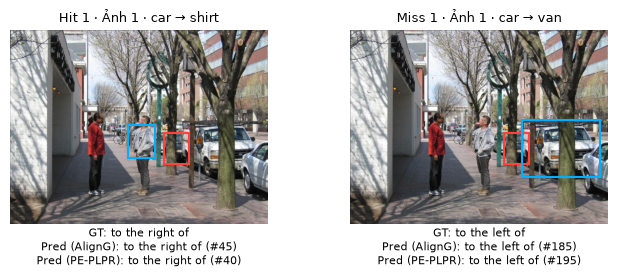

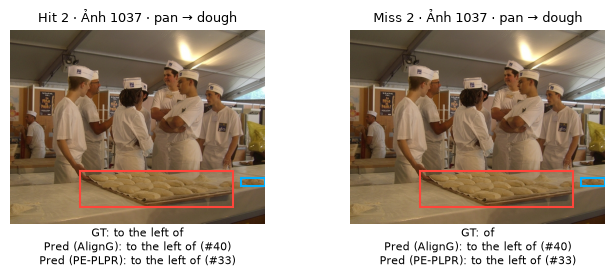

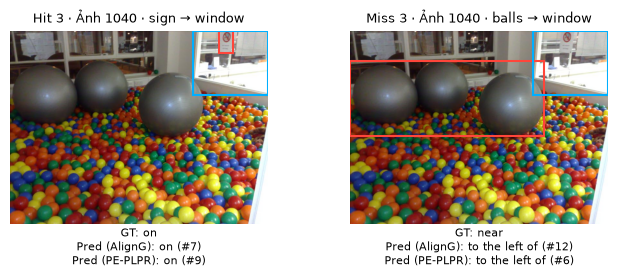

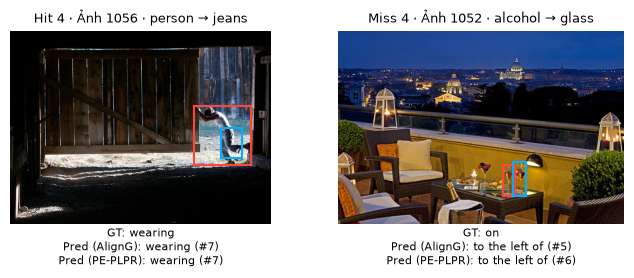

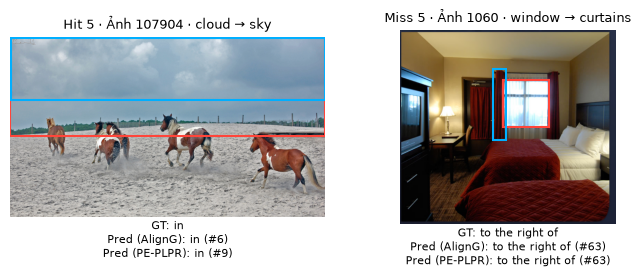

In [8]:
output = figures / 'gqa-validation-cases.pdf'
with zipfile.ZipFile(archive) as images, PdfPages(output) as pdf:
    for number, pair in enumerate(zip(cases[True], cases[False], strict=True), start=1):
        fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.8))
        fig.subplots_adjust(left=.025, right=.975, bottom=.22, top=.91, wspace=.08)
        for ax, status, row in zip(axes, ('Hit', 'Miss'), pair, strict=True):
            image_id = row['image_id']
            draw_case_image(ax, row, images)
            ax.set_title(f"{status} {number} · Ảnh {image_id} · {row['subject']} → {row['object']}", fontsize=9)
            ax.set_xlabel(f"GT: {row['gt']}\nPred (AlignG): {row['pred']} (#{row['rank']})" +
                          f"\nPred (PE-PLPR): {row['control']} (#{row['control_rank']})", fontsize=8, labelpad=2)
        pdf.savefig(fig, dpi=180)
        plt.show()
        plt.close(fig)
graphs.close()

In [9]:
# Recall theo lớp trên test: hai predicate trái/phải và 308 predicate còn lại.
vocabulary = read('data/processed/level2/gqa-v1/manifest.json')['vocabulary']['predicate_to_idx']
directional_ids = {str(vocabulary[p]) for p in ('to the left of', 'to the right of')}
group_rows = []
for model in ('pe-pl', 'pe-plpr', 'pe-plpr-aligng'):
    for seed in summary['models'][model]['seeds']:
        gc = read(report / model / str(seed) / 'result.json')['metrics']['gc']
        recalls = pd.Series({i: row['R@50'] for i, row in gc['per_predicate'].items()})
        is_directional = recalls.index.isin(directional_ids)
        assert len(recalls) == 310 and is_directional.sum() == 2
        assert abs(recalls.mean() - gc['mR@50']) < 1e-10
        group_rows.append({'model': model, 'seed': seed, '2 lớp trái/phải': 100*recalls[is_directional].mean(),
                           '308 lớp còn lại': 100*recalls[~is_directional].mean()})
display(pd.DataFrame(group_rows).groupby('model')[['2 lớp trái/phải', '308 lớp còn lại']].mean().round(2))

,2 lớp trái/phải,308 lớp còn lại
model,,
pe-pl,86.51,2.86
pe-plpr,86.59,3.53
pe-plpr-aligng,86.54,4.09
